# Day 43 — Finding Groups Nobody Labelled

## K-Means clustering

**Boston University · Data Science Program**

---

For twelve days every model has been handed a column of correct answers to copy.
Today that column is gone.

> **Clustering means finding structure that was already in the data, without ever
> being told what the structure is.**

| | |
|---|---|
| 1 | Meet 240 unlabelled customers |
| 2 | Write the four-line algorithm yourself, and watch it stop |
| 3 | See why inertia cannot choose `k`, and what can |
| 4 | Break it three ways: bad scaling, bad luck, bad shapes |
| 5 | Turn the clusters into a sentence a manager would act on |

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.simplefilter("ignore")

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.datasets import make_moons, make_blobs

plt.rcParams["figure.figsize"] = (6.4, 4.6)
TEAL, CORAL, VIOLET, INK = "#1F9E86", "#E05C45", "#8268B5", "#131F33"
COLS = [TEAL, CORAL, VIOLET, "#3E7CB1", "#F0A530"]

def show(X, labels=None, centres=None, title="", ax=None):
    ax = ax or plt.gca()
    c = "#9AA8BE" if labels is None else [COLS[l] for l in labels]
    ax.scatter(X[:, 0], X[:, 1], c=c, s=20, edgecolors="white", linewidths=.4, zorder=3)
    if centres is not None:
        ax.scatter(centres[:, 0], centres[:, 1], marker="X", s=300, c=INK,
                   edgecolors="white", linewidths=1.8, zorder=6)
    ax.set_title(title, fontsize=11)
    ax.set_xticks([]); ax.set_yticks([])

print("ready")

ready


---
# 1 · 240 customers, and nobody has labelled them

A food delivery app knows two things about each customer last month: **how many times
they ordered**, and **their average order value**. That is all. No segments, no tags.

rows: 240
orders      1.0 to   25.3   spread    6.77
value     132.7 to 1034.2   spread  266.23

the value column varies 39x more than the orders column


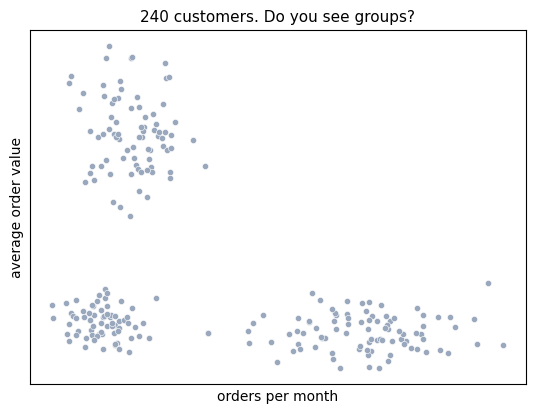

In [2]:
def load_customers(seed=43):
    r = np.random.default_rng(seed)
    a = np.c_[r.normal(18.0, 3.1, 90), r.normal(240, 45, 90)]    # order a lot, small baskets
    b = np.c_[r.normal(3.6, 1.2, 70), r.normal(255, 48, 70)]     # order rarely, small baskets
    c = np.c_[r.normal(5.2, 1.7, 80), r.normal(790, 100, 80)]    # order rarely, big baskets
    X = np.vstack([a, b, c])
    truth = np.r_[np.zeros(90), np.ones(70), np.full(80, 2)].astype(int)
    X[:, 0] = X[:, 0].clip(1, None); X[:, 1] = X[:, 1].clip(80, None)
    i = r.permutation(len(X))
    return X[i], truth[i]

X, TRUTH = load_customers()      # TRUTH is for checking at the END. The model never sees it.

print("rows:", len(X))
print(f"orders   {X[:,0].min():6.1f} to {X[:,0].max():6.1f}   spread {X[:,0].std():7.2f}")
print(f"value    {X[:,1].min():6.1f} to {X[:,1].max():6.1f}   spread {X[:,1].std():7.2f}")
print(f"\nthe value column varies {X[:,1].std()/X[:,0].std():.0f}x more than the orders column")

show(X, title="240 customers. Do you see groups?")
plt.xlabel("orders per month"); plt.ylabel("average order value")
plt.show()

You can probably see three clumps. The point of today is that **a computer has to find
them without eyes**, and the way it does that turns out to be four lines long.

> `TRUTH` exists only so we can check our work at the very end. In a real project it
> does not exist at all — that is the whole situation.

---
# 2 · Write the algorithm yourself

Four lines, in English:

1. Pick `k`, and drop `k` centres at random
2. **Assign** every point to its nearest centre
3. **Move** each centre to the middle of the points it caught
4. Repeat 2–3 until nothing changes

Scale first — K-Means measures distance, and section 4 shows what happens if you skip it.

In [3]:
Z = StandardScaler().fit_transform(X)

def assign(Z, centres):
    """Step 2: each point goes to its nearest centre."""
    d = ((Z[:, None, :] - centres[None, :, :]) ** 2).sum(axis=2)   # squared distances
    return d.argmin(axis=1), d

def move(Z, labels, k):
    """Step 3: each centre moves to the mean of its own points."""
    return np.array([Z[labels == j].mean(axis=0) for j in range(k)])

def inertia_of(Z, labels, centres):
    """Total squared distance from each point to ITS OWN centre."""
    return float(((Z - centres[labels]) ** 2).sum())

# --- one single step, so you can see each piece work -------------------
rng = np.random.default_rng(7)
centres = Z[rng.choice(len(Z), 3, replace=False)].copy()
labels, _ = assign(Z, centres)
print("after the first assignment, inertia =", round(inertia_of(Z, labels, centres), 2))

centres = move(Z, labels, 3)
print("after moving the centres,    inertia =", round(inertia_of(Z, labels, centres), 2))
print("\n...moving the centres lowered it, without touching a single label.")

after the first assignment, inertia = 220.7
after moving the centres,    inertia = 145.31

...moving the centres lowered it, without touching a single label.


## 2.1 · Now the whole loop

Keep going until an assignment changes nobody's mind.

In [4]:
def my_kmeans(Z, k, seed=7, max_iter=100):
    rng = np.random.default_rng(seed)
    centres = Z[rng.choice(len(Z), k, replace=False)].copy()
    prev = None
    for step in range(max_iter):
        labels, _ = assign(Z, centres)
        changed = None if prev is None else int((labels != prev).sum())
        print(f"  step {step+1}:  inertia {inertia_of(Z, labels, centres):8.2f}"
              + (f"   points that changed cluster: {changed}" if changed is not None else ""))
        if prev is not None and (labels == prev).all():
            print(f"\n  nothing moved -- converged after {step+1} passes")
            return labels, centres
        prev = labels
        centres = move(Z, labels, k)
    return labels, centres

my_labels, my_centres = my_kmeans(Z, 3)

  step 1:  inertia   220.70
  step 2:  inertia    93.46   points that changed cluster: 48
  step 3:  inertia    42.50   points that changed cluster: 6
  step 4:  inertia    41.51   points that changed cluster: 0

  nothing moved -- converged after 4 passes


my inertia       41.51
sklearn inertia  30.7
same answer      False


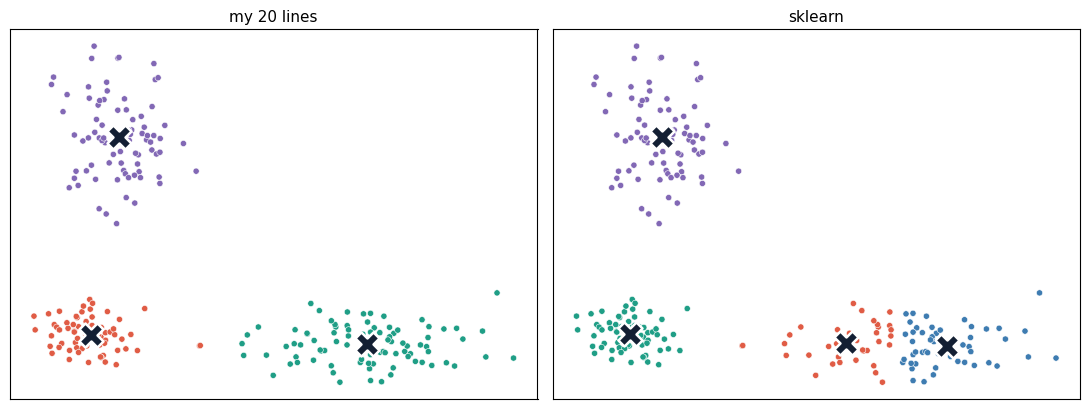

In [18]:
sk = KMeans(n_clusters=4, n_init=10, random_state=0).fit(Z)

print("my inertia      ", round(inertia_of(Z, my_labels, my_centres), 2))
print("sklearn inertia ", round(sk.inertia_, 2))
print("same answer     ", abs(inertia_of(Z, my_labels, my_centres) - sk.inertia_) < 1e-6)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
show(Z, my_labels, my_centres, "my 20 lines", ax=axes[0])
show(Z, sk.labels_, sk.cluster_centers_, "sklearn", ax=axes[1])
plt.tight_layout(); plt.show()

**Four passes over 240 customers.** No gradient descent, no learning rate, no epochs —
and the twenty lines above match scikit-learn exactly.

(The *colours* may differ between the two pictures. Cluster numbering is arbitrary:
calling a group "0" or "2" carries no meaning, which is why we never compare cluster
labels directly.)

## 2.2 · Why it is guaranteed to stop

Look at the inertia column: it fell every single step. That is not luck.

- **Assigning** each point to its *nearest* centre cannot make any distance longer.
- **Moving** a centre to the *mean* puts it at the single best spot for those points.

Both steps can only lower inertia, and there are finitely many ways to split 240 points
into 3 groups — so it must run out of room and stop.

> **But guaranteed to stop is not guaranteed to be right.** The loop halts the moment
> nothing moves, and "nothing moves" can happen at a bad arrangement. Section 4.2.

---
# 3 · Choosing k

We told it `k=3`. Nobody told *us*. Here is the obvious idea, and why it fails.

In [19]:
ks = range(1, 11)
inertias, sils = [], []
for k in ks:
    km = KMeans(k, n_init=10, random_state=0).fit(Z)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(Z, km.labels_) if k > 1 else np.nan)

print(f"{'k':>3}  {'inertia':>9}  {'drop from last':>15}  {'silhouette':>11}")
for i, k in enumerate(ks):
    drop = "" if i == 0 else f"{inertias[i-1] - inertias[i]:15.1f}"
    sil = "" if k == 1 else f"{sils[i]:11.4f}"
    print(f"{k:>3}  {inertias[i]:9.1f}  {drop}  {sil}")

  k    inertia   drop from last   silhouette
  1      480.0    
  2      192.2            287.8       0.5841
  3       41.5            150.7       0.7420
  4       30.7             10.8       0.6419
  5       22.2              8.5       0.5501
  6       18.9              3.4       0.5144
  7       16.2              2.7       0.4949
  8       14.6              1.6       0.4803
  9       13.2              1.4       0.3505
 10       11.8              1.4       0.3580


**Read the inertia column downwards: it never stops falling.** That is not a property of
this dataset — it is arithmetic. More centres means everybody is closer to one. At
`k = 240` every customer *is* a centre and inertia is exactly 0.

So "choose the `k` with the lowest inertia" always answers *give every row its own
cluster*, which is useless. Two things actually work:

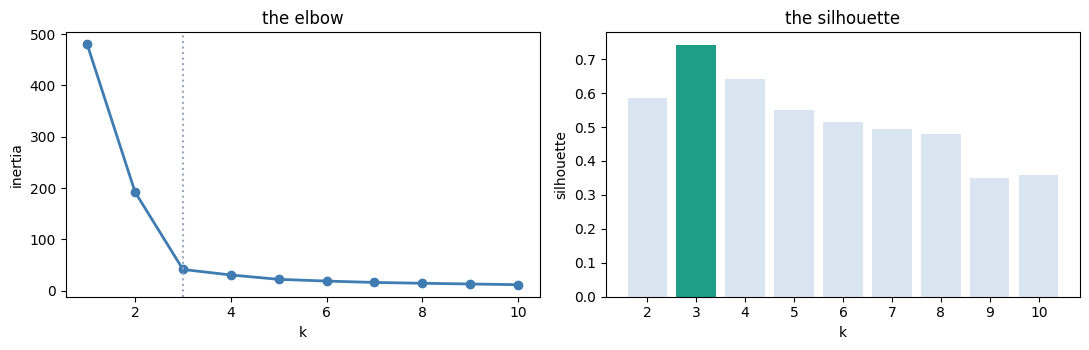

silhouette peaks at k = 3 with 0.742


In [7]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6))

a1.plot(list(ks), inertias, "-o", color="#3E7CB1", lw=2)
a1.axvline(3, color="#9AA8BE", ls=":")
a1.set_xlabel("k"); a1.set_ylabel("inertia"); a1.set_title("the elbow")

a2.bar([str(k) for k in list(ks)[1:]], sils[1:],
       color=[TEAL if k == 3 else "#D9E6F2" for k in list(ks)[1:]])
a2.set_xlabel("k"); a2.set_ylabel("silhouette"); a2.set_title("the silhouette")
plt.tight_layout(); plt.show()

best = int(np.nanargmax(sils)) + 1
print("silhouette peaks at k =", best, "with", round(np.nanmax(sils), 4))

**The elbow.** Going 2 → 3 bought a drop of 150.7. Going 3 → 4 bought 10.8 — *fourteen
times less*. That cliff is where extra clusters stop paying for themselves.

**The silhouette.** For each point:

$$s = \frac{b - a}{\max(a,\,b)}$$

- `a` = average distance to points **in my own cluster**
- `b` = average distance to points **in the nearest other cluster**

Near **+1** the point is comfortably where it belongs; near **0** it is on the border;
**negative** means it is in the wrong cluster. Unlike inertia, this can get *worse* when
`k` is wrong, so it has a real peak — here at `k = 3`.

---
# 4 · Three ways to get a confident, wrong answer

## 4.1 · Forgetting to scale

agreement with the real groups (1.0 = perfect):
  raw columns   0.4668
  scaled        0.9752


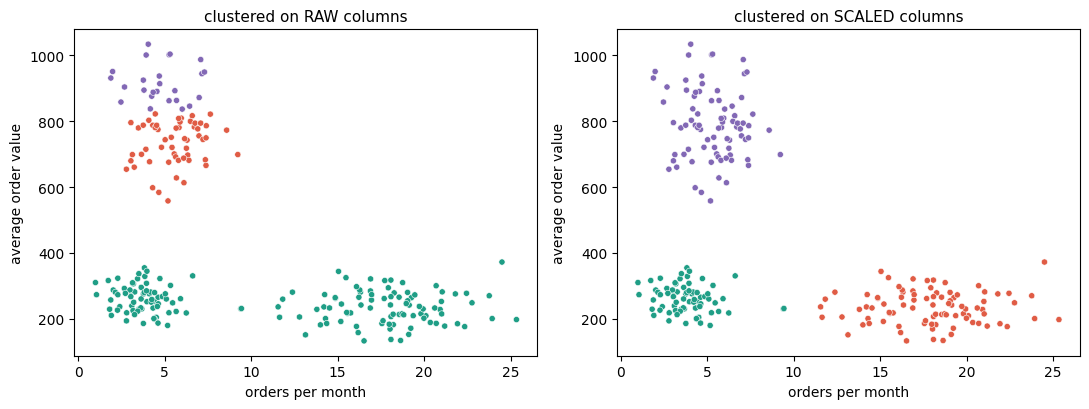

In [8]:
raw = KMeans(3, n_init=10, random_state=0).fit(X)        # the RAW columns
scaled = KMeans(3, n_init=10, random_state=0).fit(Z)     # standardised

print("agreement with the real groups (1.0 = perfect):")
print("  raw columns  ", round(adjusted_rand_score(TRUTH, raw.labels_), 4))
print("  scaled       ", round(adjusted_rand_score(TRUTH, scaled.labels_), 4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, lab, t in [(axes[0], raw.labels_, "clustered on RAW columns"),
                   (axes[1], scaled.labels_, "clustered on SCALED columns")]:
    ax.scatter(X[:, 0], X[:, 1], c=[COLS[l] for l in lab], s=20,
               edgecolors="white", linewidths=.4)
    ax.set_title(t, fontsize=11)
    ax.set_xlabel("orders per month"); ax.set_ylabel("average order value")
plt.tight_layout(); plt.show()

Look at the left picture: the boundaries are **horizontal**. The raw model only ever cut
on price, because value varies 39× more than orders, so "distance" meant "difference in
rupees" and nothing else. It lumped all 160 small-basket customers together and split the
families in two.

**0.467 → 0.975 from one line of code.** K-Means is a distance method; scaling is not
optional.

## 4.2 · Bad luck with the starting positions

30 single-start runs produced 3 different answers: [41.51, 179.73, 203.4]
stuck in a worse one: 10 of 30


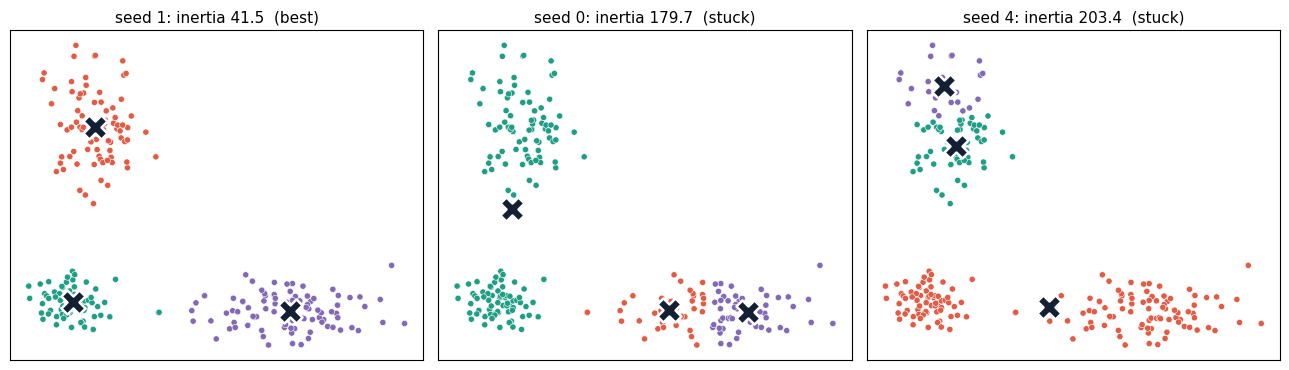

In [9]:
results = {}
for seed in range(30):
    km = KMeans(3, n_init=1, init="random", random_state=seed).fit(Z)
    results[seed] = round(km.inertia_, 2)

distinct = sorted(set(results.values()))
best = min(distinct)
print("30 single-start runs produced", len(distinct), "different answers:", distinct)
print("stuck in a worse one:", sum(1 for v in results.values() if v > best), "of 30")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, seed in zip(axes, [1, 0, 4]):
    km = KMeans(3, n_init=1, init="random", random_state=seed).fit(Z)
    good = abs(km.inertia_ - best) < 0.01
    show(Z, km.labels_, km.cluster_centers_,
         f"seed {seed}: inertia {km.inertia_:.1f}" + ("  (best)" if good else "  (stuck)"),
         ax=ax)
plt.tight_layout(); plt.show()

In [10]:
for n in [1, 2, 5, 10]:
    hits = sum(1 for s in range(30)
               if abs(KMeans(3, n_init=n, init="random", random_state=s).fit(Z).inertia_
                      - best) < 0.01)
    print(f"  n_init={n:2d}  reached the best answer in {hits}/30 runs")

  n_init= 1  reached the best answer in 20/30 runs
  n_init= 2  reached the best answer in 24/30 runs
  n_init= 5  reached the best answer in 30/30 runs
  n_init=10  reached the best answer in 30/30 runs


The loop stops when nothing moves — and that can happen at a bad arrangement. The fix is
embarrassingly simple: **run it several times and keep the lowest inertia**. That is
exactly what `n_init` does, and sklearn already defaults to 10.

> `init='k-means++'` (also the default) spreads the starting centres out on purpose
> instead of picking them at random, which makes a bad start much less likely in the
> first place.

## 4.3 · Shapes it cannot see

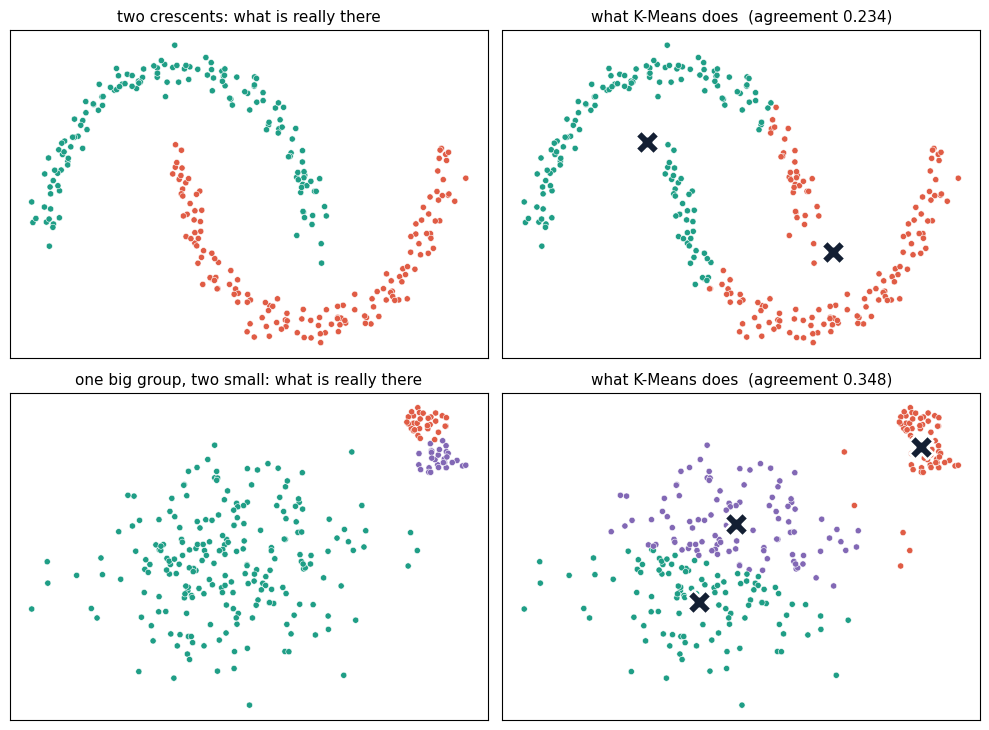

In [11]:
Xm, ym = make_moons(300, noise=0.06, random_state=0)
Xu, yu = make_blobs(n_samples=[220, 30, 30], centers=[[0, 0], [7, 7], [7.6, 5.2]],
                    cluster_std=[2.4, 0.42, 0.42], random_state=3)

fig, axes = plt.subplots(2, 2, figsize=(10, 7.4))
for row, (D, truth, k, name) in enumerate([(Xm, ym, 2, "two crescents"),
                                           (Xu, yu, 3, "one big group, two small")]):
    km = KMeans(k, n_init=10, random_state=0).fit(D)
    show(D, truth, title=f"{name}: what is really there", ax=axes[row][0])
    show(D, km.labels_, km.cluster_centers_,
         f"what K-Means does  (agreement {adjusted_rand_score(truth, km.labels_):.3f})",
         ax=axes[row][1])
plt.tight_layout(); plt.show()

K-Means puts a centre somewhere and claims everything nearest to it — so **every cluster
it can possibly draw is a round blob**. Give it crescents and it slices through them.
Give it one big loose group and two small tight ones and it splits the big one and merges
the small ones.

These are not bugs. They are the three assumptions you make whenever you call it:

| Assumption | Broken by |
|---|---|
| clusters are roughly **round** | crescents, rings, long thin shapes |
| clusters are roughly the **same size** | one dominant group and several small ones |
| you already **know k** | nearly every real dataset |

## 4.4 · And the trap in the scoring

In [12]:
km_m = KMeans(2, n_init=10, random_state=0).fit(Xm)
print(f"{'':16}{'silhouette':>12}{'agreement with truth':>24}")
print(f"{'our customers':16}{silhouette_score(Z, scaled.labels_):>12.4f}"
      f"{adjusted_rand_score(TRUTH, scaled.labels_):>24.4f}")
print(f"{'two crescents':16}{silhouette_score(Xm, km_m.labels_):>12.4f}"
      f"{adjusted_rand_score(ym, km_m.labels_):>24.4f}")

                  silhouette    agreement with truth
our customers         0.7420                  0.9752
two crescents         0.4878                  0.2343


A silhouette of **0.488** on the crescents is middling — the kind of number you would
shrug at and accept. The clustering behind it is almost worthless.

Silhouette asks *"are these blobs tight and well separated?"* — and two half-crescents
genuinely are fairly tight and fairly separated. It answers its own question honestly. It
is simply **not asking whether the groups are the right ones**, and nothing can, because
nobody labelled the data.

> So what do you do? **Plot it**, then show the clusters to somebody who knows the
> subject. In unsupervised learning a person saying *"yes, those are our three customer
> types"* is not a weak substitute for a metric — it is the strongest evidence available.

---
# 5 · The part that is actually worth money

Clusters are useless until someone can **name them** and **do something different** to
each. Profile them.

In [13]:
import pandas as pd

df = pd.DataFrame(X, columns=["orders", "value"])
df["cluster"] = scaled.labels_
df["monthly_spend"] = df["orders"] * df["value"]

profile = df.groupby("cluster").agg(
    customers=("orders", "size"),
    orders_per_month=("orders", "mean"),
    avg_order=("value", "mean"),
    monthly_spend=("monthly_spend", "mean")).round(1)
print(profile)

         customers  orders_per_month  avg_order  monthly_spend
cluster                                                       
0               72               3.9      260.6          999.8
1               88              17.9      234.2         4195.8
2               80               5.3      789.7         4177.8


Now read it as a person rather than a model:

| Cluster | Who they probably are |
|---|---|
| ~18 orders of ~₹234 | **students** — order constantly, small baskets |
| ~5 orders of ~₹790 | **families** — order rarely, big baskets |
| ~4 orders of ~₹261 | **occasional users** — rare and small |

### The finding that would change a decision

Two of these groups are worth **almost exactly the same per month** — about ₹4,196 and
₹4,178 — and they look nothing alike. One orders seventeen times at ₹234 a go; the other
orders five times at ₹790.

A "top customers" list sorted by spend would mix them together and treat them
identically. But **free delivery** is worth a great deal to the first group and almost
nothing to the second, while a **bulk discount** is the other way round.

The clustering did not just sort the customers. It found that the two most valuable
segments need *opposite* campaigns. That sentence — not the inertia, not the silhouette —
is why anyone runs K-Means.

In [14]:
# finally: how well did we do? (only possible because this is a teaching dataset)
print("agreement with the real groups:",
      round(adjusted_rand_score(TRUTH, scaled.labels_), 4))
print("\nThe model was never shown TRUTH. It found the three groups from two columns.")

agreement with the real groups: 0.9752

The model was never shown TRUTH. It found the three groups from two columns.


---
# 6 · Summary

| | |
|---|---|
| **The shift** | No answer column, no accuracy. You judge the result by looking at it. |
| **The loop** | Drop `k` centres, assign each point to the nearest, move each centre to the middle, repeat. |
| **Inertia** | Total squared distance to your own centre. Both steps can only lower it, so it always stops. |
| **Choosing k** | Never by minimising inertia — it falls forever and hits 0 at `k = n`. Use the elbow and the silhouette. |
| **Silhouette** | `(b − a) / max(a, b)`. Peaked at 0.742 for `k = 3` — right, without being told. |
| **Scaling** | Compulsory. 0.467 unscaled against 0.975 scaled. |
| **Restarts** | 10 of 30 single starts got stuck. Leave `n_init` at 10. |
| **The limits** | Round, similar-sized clusters only. On crescents: 0.234, with a respectable-looking silhouette. |

### Next: Day 44

K-Means had to be told `k`, and could only draw round blobs. Next we meet two methods
that fix exactly those two problems — **hierarchical clustering**, which lets you choose
`k` *after* looking, and **DBSCAN**, which finds clusters of any shape and is allowed to
say "this point is just noise".